# **[1] Online Retail - Custom Clustering**

* https://www.kaggle.com/datasets/vijayuv/onlineretail
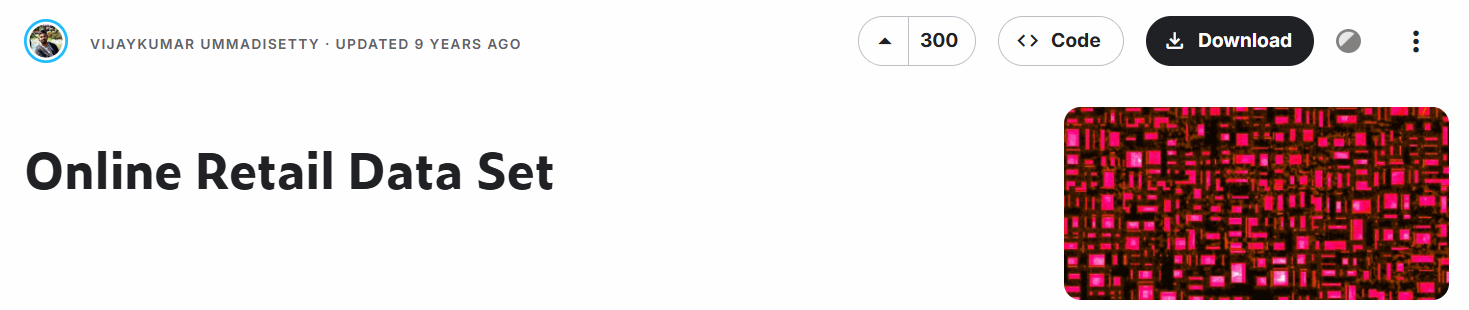

In [1]:
from sklearn import set_config
set_config(display="text")
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

import warnings
warnings.filterwarnings('ignore')

#-------------------- 차트 관련 속성 (한글처리, 그리드) -----------
plt.rcParams['font.family']= 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

from sklearn.model_selection import train_test_split           #---- 문제답 분리


from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_samples, silhouette_score

from sklearn.linear_model import LogisticRegression             #---- 분류모델(선형모델)
from sklearn.ensemble import RandomForestClassifier             #---- 분류모델(트리모델)   
from sklearn.ensemble import VotingClassifier, VotingRegressor  #---- 분류모델(앙상블)  

from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, precision_recall_curve, average_precision_score #---- 평가 메트릭스
from sklearn.metrics import roc_auc_score, roc_curve     #---- 평가 메트릭스
from sklearn.metrics import confusion_matrix, classification_report

from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold, cross_val_score, cross_validate  #----교차검증

from sklearn.preprocessing import LabelEncoder, OneHotEncoder                       #-----인코딩(글자->숫자변경)
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler        #-----정규화(스케일링)
from sklearn.decomposition import PCA                                               #-----차원축소


* InvoiceNo: 영수증 번호 (고유 주문 번호, 'C'로 시작하면 취소)
* StockCode: 상품 코드 (고유 상품 번호)
* Description: 상품명 (상품 이름 및 설명)
* Quantity: 주문 수량 (취소/반품 시 음수)
* InvoiceDate: 주문 일시 (거래가 발생한 날짜와 시간)
* UnitPrice: 상품 단가 (개당 가격)
* CustomerID: 고객 ID (고유 회원 번호)
* Country: 주문 국가 (고객 거주 국가)

# **RFM 마케팅 분석**
* Recency (최근성): 고객이 얼마나 최근에 구매(또는 방문·활동)했는가 - InvoiceDate	
* Frequency (빈도): 고객이 일정 기간 동안 얼마나 자주 구매했는가 - InvoiceNo, StockCode
* Monetary (금액): 고객이 총 얼마나 많은 금액을 지출했는가 - UnitPrice * Quantity	

In [2]:
df = pd.read_csv("../datas/online/OnlineRetail.csv",  parse_dates=['InvoiceDate'], encoding='ISO-8859-1')
df.head(2)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df.columns = df.columns.str.lower()

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   invoiceno    541909 non-null  str           
 1   stockcode    541909 non-null  str           
 2   description  540455 non-null  str           
 3   quantity     541909 non-null  int64         
 4   invoicedate  541909 non-null  datetime64[us]
 5   unitprice    541909 non-null  float64       
 6   customerid   406829 non-null  float64       
 7   country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 33.1 MB


# **전처리 & 가공**

* 분석 제외 
    * 비회원 : CustomerID 결측
    * 주요 타켓 : Country == 'United Kingdom'
    * 취소건은 제외 : InvoiceNo(고유 주문 번호, 'C'로 시작하면 취소)
    * 상품 : StockCode, Description
    * 파생피쳐 : Price = Quantity * UnitPrice
* 컬럼 소문자

In [5]:
df['country'].value_counts()[:3]

country
United Kingdom    495478
Germany             9495
France              8557
Name: count, dtype: int64

## 비회원 : customerid 결측

In [6]:
print(df.shape)
df = df.dropna(subset=['customerid'])
print(df.shape)

(541909, 8)
(406829, 8)


## 주요 타켓 : Country == 'United Kingdom'

In [7]:
df.columns

Index(['invoiceno', 'stockcode', 'description', 'quantity', 'invoicedate',
       'unitprice', 'customerid', 'country'],
      dtype='str')

In [8]:
print(df.shape)
df = df[df['country'] == 'United Kingdom']
print(df.shape)

(406829, 8)
(361878, 8)


## 상품 : StockCode, Description

In [9]:
print(df.shape)
df = df.drop(columns=['stockcode','description'])
print(df.shape)

(361878, 8)
(361878, 6)


## 취소건은 제외 
* InvoiceNo(고유 주문 번호, 'C'로 시작하면 취소)

In [10]:
df[df['invoiceno'].str[:1] == 'C'].shape

(7533, 6)

In [11]:
df[df['quantity']<0].shape, df.shape

((7533, 6), (361878, 6))

* 주문취소율

In [12]:
(df[df['quantity']<0].shape[0] / df.shape[0] ) * 100

2.0816407739624956

In [13]:
print(df.shape)
df = df.iloc[df['quantity']>=0 , :]
print(df.shape)

(361878, 6)
(354345, 6)


## 파생피쳐 : Price = Quantity * UnitPrice

In [14]:
df['price'] = df['quantity'] * df['unitprice']
df.head(2)

,invoiceno,quantity,invoicedate,unitprice,customerid,country,price
0,536365,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [15]:
#삭제 : quantity	invoicedate	unitprice	

In [16]:
print(df.shape)
df = df.drop(columns=['unitprice','quantity'])
print(df.shape)

(354345, 7)
(354345, 5)


* price 0인 고객은 빈도를 위해 가져감

In [17]:
df[df['price'] == 0].groupby('customerid')['customerid'].count().sort_values(ascending=False)[:3]

customerid
13081.0    4
13985.0    2
13014.0    1
Name: customerid, dtype: int64

In [18]:
df.head(2)

,invoiceno,invoicedate,customerid,country,price
0,536365,2010-12-01 08:26:00,17850.0,United Kingdom,15.30
1,536365,2010-12-01 08:26:00,17850.0,United Kingdom,20.34


## 데이터 수집 기간

In [19]:
df['invoicedate'].min() , df['invoicedate'].max()

(Timestamp('2010-12-01 08:26:00'), Timestamp('2011-12-09 12:49:00'))

In [20]:
df['diff'] = df['invoicedate'].max() - df['invoicedate']

In [21]:
df['diff'] = df['diff'].apply(lambda d : d.days +1)

##  불필요한 컬럼 삭제

In [22]:
df = df.drop(columns=['country', 'invoicedate'])

In [23]:
df = df.rename(columns={"diff":"R", "invoiceno":"F", "price":"M"})

## 최종 분석 데이터

In [24]:
df.head(2)

,F,customerid,M,R
0,536365,17850.0,15.30,374
1,536365,17850.0,20.34,374


# **user별 RFM 분석 군집모델**
* R : max
* F : count
* M : sum
* ** 표준화 - PCA - KMeans - 엘보차트[K?] - silhouette_score, scatter **

## 최종 분석 데이터

In [25]:
rfm_df = df.groupby("customerid").agg(  {"R":"max",  "F":"count",  "M":"sum"}  )
rfm_df.head(2)

,R,F,M
customerid,,,
12346.0,326,1,77183.60
12747.0,369,103,4196.01


In [26]:
rfm_df.info()

<class 'pandas.DataFrame'>
Index: 3921 entries, 12346.0 to 18287.0
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   R       3921 non-null   int64  
 1   F       3921 non-null   int64  
 2   M       3921 non-null   float64
dtypes: float64(1), int64(2)
memory usage: 122.5 KB


## K값 튜닝 적정 K 찾기(엘보)

In [27]:
def MY_SPCA_CHART(rfm_df) : 
    # ---------------- 표준화 & PCA  -----------------
    ss =  StandardScaler()
    ss.fit(rfm_df)
    scale_res = ss.transform(rfm_df)
    
    pca = PCA(n_components=2, random_state=1234)
    pca_res = pca.fit_transform(scale_res)
    print( f"각각의 PC 설명력 : {pca.explained_variance_ratio_}" )
    print( f"PCA 전체 설명력 : {pca.explained_variance_ratio_.sum():.3f}" )
    
    pca_df = pd.DataFrame(pca_res, columns=['pc1','pc2'])
    pca_df.head(2)
    
    inertia_list = []
    k_list = [2, 3, 4, 5]
    
    # 총 5개의 subplot 생성 (4개는 K별 산점도, 마지막 1개는 엘보우 차트)
    fig, axes = plt.subplots(1, len(k_list) + 1, figsize=(20, 5))
    
    for i, MY_K in enumerate(k_list):
        kmodel = KMeans(n_clusters=MY_K, random_state=1234)
        
        # 1. 학습 및 예측
        # (이미 pc1, pc2만 있는 데이터프레임이므로 변수명만 넣어주셔도 안전합니다)
        pred_label = kmodel.fit_predict(pca_df[['pc1','pc2']])
        pca_df['pred_label'] = pred_label
        rfm_df[f'pred_label_{MY_K}'] = pred_label 

        sscore = silhouette_score(pca_df[['pc1','pc2']], pred_label)
        print(f"{MY_K} {sscore:.4f}")
        
        sns.scatterplot(data=pca_df, x="pc1", y="pc2", hue="pred_label", ax=axes[i], legend=False)
        axes[i].set_title(f"K = {MY_K}")
        
        #중심점(CH)
        ch = kmodel.cluster_centers_
        axes[i].scatter(ch[:, 0], ch[:, 1], marker="X", s=200, 
                        color="red", edgecolor="black", linewidth=1.5, label="Center")
    
        inertia_list.append(kmodel.inertia_)
        print(inertia_list)
    
    # ----------- 엘보차트 -------------
    axes[-1].plot([2,3,4,5], inertia_list, marker='o', color='purple', linestyle='--')
    axes[-1].set_title("엘보차트(적정K값)")
    
    plt.tight_layout()
    plt.show()

    return rfm_df

각각의 PC 설명력 : [0.48814527 0.28905088]
PCA 전체 설명력 : 0.777
2 0.5304
[5912.709856434884]
3 0.5546
[5912.709856434884, 2905.3716307735513]
4 0.5786
[5912.709856434884, 2905.3716307735513, 1942.9929216935357]
5 0.5543
[5912.709856434884, 2905.3716307735513, 1942.9929216935357, 1490.1386809795658]


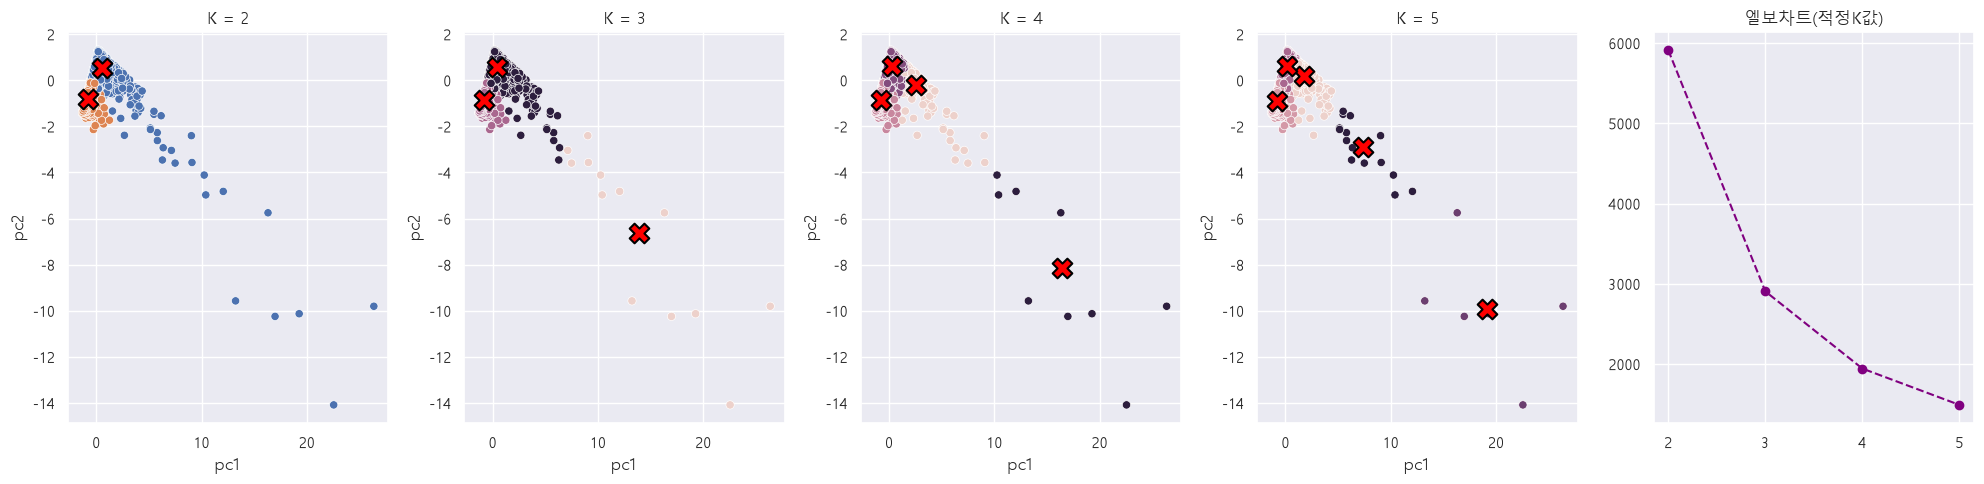

,R,F,M,pred_label_2,pred_label_3,pred_label_4,pred_label_5
customerid,,,,,,,
12346.0,326,1,77183.60,0,2,0,4
12747.0,369,103,4196.01,0,2,2,2


In [28]:
res_df = MY_SPCA_CHART(rfm_df[['R','F','M']])
res_df.head(2)

## 로그변환

In [29]:
rfm_df.head(2)

,R,F,M
customerid,,,
12346.0,326,1,77183.60
12747.0,369,103,4196.01


In [30]:
res = np.log1p(rfm_df)
res.head(2)

,R,F,M
customerid,,,
12346.0,5.789960,0.693147,11.253955
12747.0,5.913503,4.644391,8.342128


각각의 PC 설명력 : [0.6551519  0.26525569]
PCA 전체 설명력 : 0.920
2 0.4190
[5735.336810527449]
3 0.4427
[5735.336810527449, 3671.001671516112]
4 0.3985
[5735.336810527449, 3671.001671516112, 2738.696919994652]
5 0.4020
[5735.336810527449, 3671.001671516112, 2738.696919994652, 2263.84339813693]


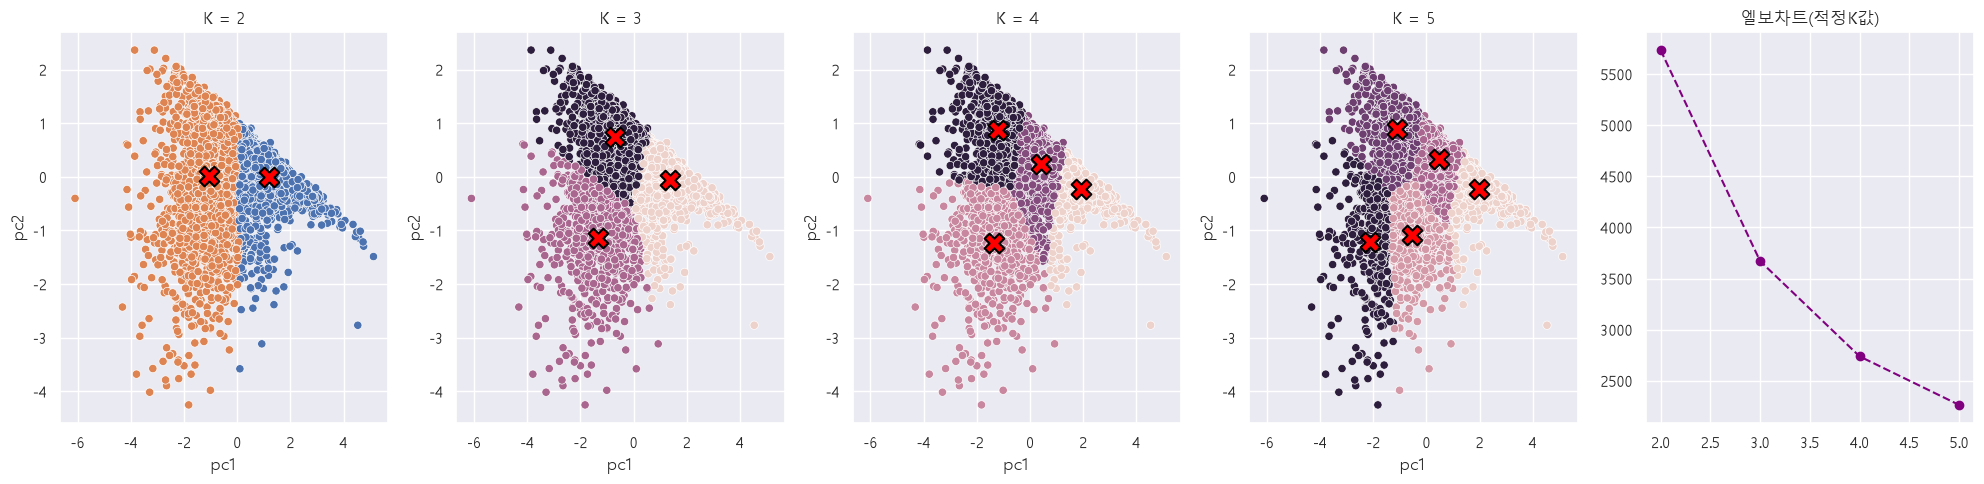

,R,F,M,pred_label_2,pred_label_3,pred_label_4,pred_label_5
customerid,,,,,,,
12346.0,5.789960,0.693147,11.253955,0,0,2,2
12747.0,5.913503,4.644391,8.342128,0,0,0,0


In [31]:
#res_df = MY_SPCA_CHART(np.log1p(rfm_df[['R','F','M']]))
res_df = MY_SPCA_CHART(res)
res_df.head(2)

# **군집 분석**

In [32]:
res_df[['R','F','M']] = np.expm1(res_df[['R','F','M']])

In [33]:
res_df.head(2)

,R,F,M,pred_label_2,pred_label_3,pred_label_4,pred_label_5
customerid,,,,,,,
12346.0,326.0,1.0,77183.60,0,0,2,2
12747.0,369.0,103.0,4196.01,0,0,0,0


In [34]:
res = res_df.groupby("pred_label_3").agg(  {"R":"max",  "F":"count",  "M":"sum"}  )
res

,R,F,M
pred_label_3,,,
0,374.0,1584,6268733.261
1,113.0,866,420713.991
2,374.0,1471,618944.302


In [35]:
res = res_df.groupby("pred_label_4").agg(  {"R":"max",  "F":"count",  "M":"sum"}  )
res

,R,F,M
pred_label_4,,,
0,374.0,854,5242242.431
1,112.0,785,372203.581
2,374.0,1352,1450263.812
3,374.0,930,243681.730


In [36]:
res = res_df.groupby("pred_label_5").agg(  {"R":"max",  "F":"count",  "M":"sum"}  )
res

,R,F,M
pred_label_5,,,
0,374.0,810,5145488.261
1,135.0,552,436614.571
2,374.0,1237,1378631.302
3,374.0,937,257322.080
4,84.0,385,90335.340


* K=3, K=4까지는 살아있는 활성 고객이 단 하나(R=112~113)로 뭉뚱그려져 있어서 마케팅이 획일적일 수밖에 없었습니다.
* K=5에 이르러서야 막 들어온 새싹 고객(그룹 4)과 지갑을 열기 시작한 주력 고객(그룹 1)이 분리되었습니다.
* 따라서 마케팅 예산은 그룹 1(성장 유지)과 그룹 4(안착 유도)에 집중 투입하고, 휴면층 중에서는 오직 그룹 0(초고액 VIP)의 복귀에만 선별적 예산을 쓰는 것이 가장 효율적입니다.